In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftshift
from scipy.signal.windows import hann, hamming, blackman

In [3]:
f1 = 200.0
f2 = 200.25
f3 = 199.75
A1 = 4.0
A2 = 0.1 * A1
A3 = 0.01 * A1
fs = 400.0
N = 2000

In [4]:
k = np.arange(N)
x = (A1 * np.sin(2 * np.pi * f1 / fs * k) + 
     A2 * np.sin(2 * np.pi * f2 / fs * k) + 
     A3 * np.sin(2 * np.pi * f3 / fs * k))

In [5]:
w_rect = np.ones(N)
w_hann = hann(N, sym=False)
w_hamm = hamming(N, sym=False)
w_black = blackman(N, sym=False)

In [6]:
def fft2db(X):
    N_size = X.size
    Xtmp = 2 / N_size * X
    Xtmp[0] *= 1/2
    if N_size % 2 == 0:
        Xtmp[N_size//2] = Xtmp[N_size//2] / 2
    magnitude = np.abs(Xtmp)
    magnitude[magnitude < 1e-12] = 1e-12
    return 20 * np.log10(magnitude)

In [7]:
X_rect = fft(x * w_rect)
X_hann = fft(x * w_hann)
X_hamm = fft(x * w_hamm)
X_black = fft(x * w_black)

df = fs / N
f = np.arange(N) * df

In [8]:
plt.figure(figsize=(12, 10))

<Figure size 1200x1000 with 0 Axes>

<Figure size 1200x1000 with 0 Axes>

Text(0.5, 1.0, 'Znormalizowane widma DFT dla różnych okien (Zbliżenie na 198-202 Hz)')

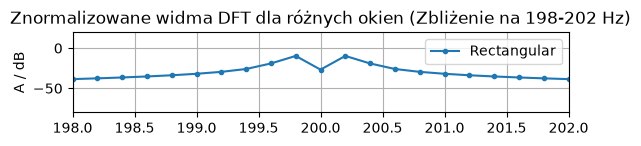

In [ ]:
plt.subplot(4, 1, 1)
plt.plot(f, fft2db(X_rect), 'C0o-', ms=3, label='Rectangular')
plt.xlim(198, 202)
plt.ylim(-80, 20)
plt.ylabel('A / dB')
plt.legend()
plt.grid(True)
plt.title('Normalized DFT spectra for different windows (Zoom on 198-202 Hz)')


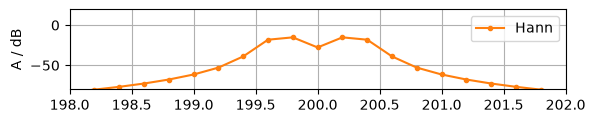

In [10]:
plt.subplot(4, 1, 2)
plt.plot(f, fft2db(X_hann), 'C1o-', ms=3, label='Hann')
plt.xlim(198, 202)
plt.ylim(-80, 20)
plt.ylabel('A / dB')
plt.legend()
plt.grid(True)

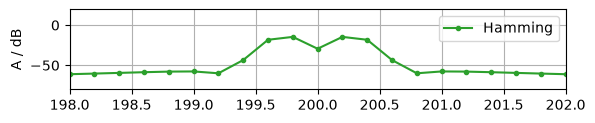

In [11]:
plt.subplot(4, 1, 3)
plt.plot(f, fft2db(X_hamm), 'C2o-', ms=3, label='Hamming')
plt.xlim(198, 202)
plt.ylim(-80, 20)
plt.ylabel('A / dB')
plt.legend()
plt.grid(True)

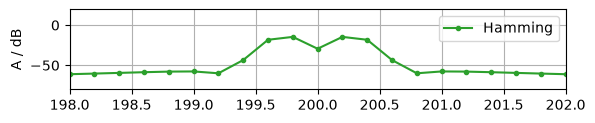

In [12]:
plt.subplot(4, 1, 3)
plt.plot(f, fft2db(X_hamm), 'C2o-', ms=3, label='Hamming')
plt.xlim(198, 202)
plt.ylim(-80, 20)
plt.ylabel('A / dB')
plt.legend()
plt.grid(True)

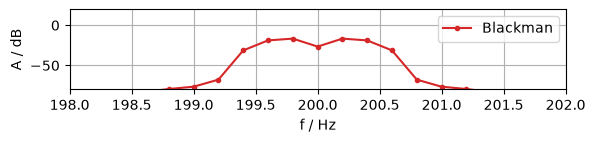

In [13]:
plt.subplot(4, 1, 4)
plt.plot(f, fft2db(X_black), 'C3o-', ms=3, label='Blackman')
plt.xlim(198, 202)
plt.ylim(-80, 20)
plt.xlabel('f / Hz')
plt.ylabel('A / dB')
plt.legend()
plt.grid(True)

In [14]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [15]:
def winDTFTdB(w):
    N_w = len(w)
    Nz = 100 * N_w
    W = np.zeros(Nz)
    W[0:N_w] = w
    W_fft = np.abs(fftshift(fft(W)))
    W_norm = W_fft / np.max(W_fft)
    W_norm[W_norm < 1e-12] = 1e-12
    W_dB = 20 * np.log10(W_norm)
    Omega = 2 * np.pi / Nz * np.arange(Nz) - np.pi
    return Omega, W_dB

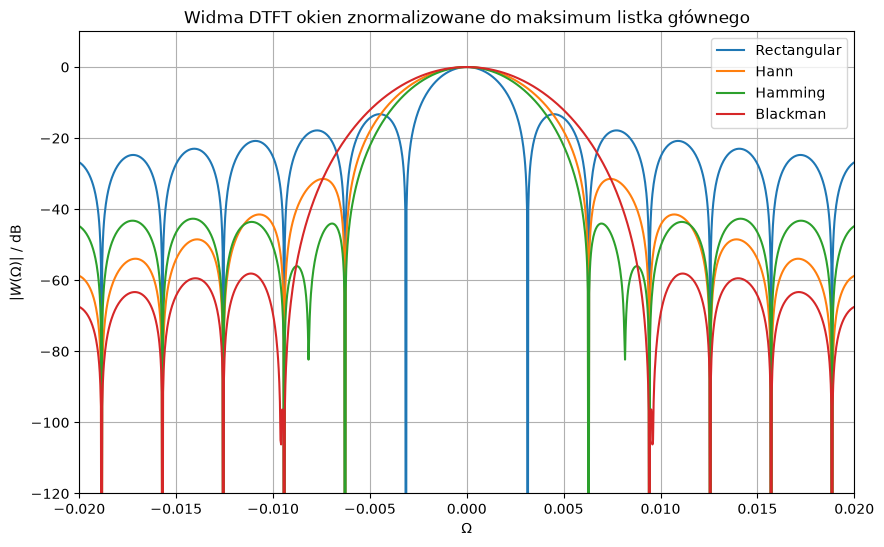

In [19]:

O_rect, W_rect_dtft = winDTFTdB(w_rect)
O_hann, W_hann_dtft = winDTFTdB(w_hann)
O_hamm, W_hamm_dtft = winDTFTdB(w_hamm)
O_black, W_black_dtft = winDTFTdB(w_black)

plt.figure(figsize=(10, 6))

plt.plot(O_rect, W_rect_dtft, label='Rectangular')
plt.plot(O_hann, W_hann_dtft, label='Hann')
plt.plot(O_hamm, W_hamm_dtft, label='Hamming')
plt.plot(O_black, W_black_dtft, label='Blackman')

plt.xlim(-0.02, 0.02)
plt.ylim(-120, 10)
plt.xlabel(r'$\Omega$')
plt.ylabel(r'$|W(\Omega)|$ / dB')
plt.title('Widma DTFT okien znormalizowane do maksimum listka głównego')
plt.legend()
plt.grid(True)
plt.show()